# Uroom Sports Analytics — Prototype ML
## Estimation du potentiel de jeunes joueurs de football

Philosophie v2 : **l'IA évalue objectivement, le scout enrichit le contexte**
- Le modèle est basé sur des données objectives (PHV, technique, physique)
- Le score scout est un signal d'alerte séparé, pas une feature ML
- Chaque score est accompagné d'un indicateur de fiabilité

In [1]:
from statsbombpy import sb

# Voir toutes les compétitions disponibles gratuitement
competitions = sb.competitions()
print(f"{len(competitions)} compétitions disponibles")
print(competitions[['competition_name', 'country_name', 'season_name']].to_string())

/Users/steveneklou/Desktop/UROOM-IA/uroom-ia/.venv/lib/python3.13/site-packages/statsbombpy/api_client.py:21: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(


75 compétitions disponibles
           competition_name               country_name season_name
0             1. Bundesliga                    Germany   2023/2024
1             1. Bundesliga                    Germany   2015/2016
2    African Cup of Nations                     Africa        2023
3          Champions League                     Europe   2018/2019
4          Champions League                     Europe   2017/2018
5          Champions League                     Europe   2016/2017
6          Champions League                     Europe   2015/2016
7          Champions League                     Europe   2014/2015
8          Champions League                     Europe   2013/2014
9          Champions League                     Europe   2012/2013
10         Champions League                     Europe   2011/2012
11         Champions League                     Europe   2010/2011
12         Champions League                     Europe   2009/2010
13         Champions League       

In [20]:
import sys
import os

PROJECT_ROOT = "/Users/steveneklou/Desktop/UROOM-IA/uroom-ia"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(1, PROJECT_ROOT)

from uroom.synthetic import generate_dataset
from uroom.features  import (
    build_feature_matrix,
    get_feature_columns,
    get_core_feature_columns,
    select_features_for_dataset,
)
from uroom.model import (
    temporal_train_test_split,
    train_model,
    evaluate_model,
    find_optimal_threshold,
    plot_feature_importance,
    predict_potential,
    explain_player,
)
from uroom.similarity import (
    ProProfileDatabase,
    build_similarity_report,
    print_similarity_report,
    build_reference_database,
    compute_trajectory_similarity,
)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='muted')
%matplotlib inline

print("Imports OK ✓")

Imports OK ✓


---
## 1. Génération des données synthétiques

In [21]:
players, snapshots = generate_dataset(
    n_players            = 500,
    pro_ratio            = 0.12,
    snapshots_per_player = 4,
)

Dataset v3 généré : 500 joueurs (60 pros [12%], 440 non-pros)
Total snapshots   : 2000
Archetypes pros     : {np.str_('early_bloomer'): np.int64(21), np.str_('inconsistent'): np.int64(10), np.str_('late_bloomer'): np.int64(13), np.str_('steady_climber'): np.int64(16)}
Archetypes non-pros : {np.str_('average'): np.int64(187), np.str_('early_specialist'): np.int64(115), np.str_('physical_dominant'): np.int64(138)}


In [22]:
sample_player   = players[0]
sample_snapshot = [s for s in snapshots if s.player_id == sample_player.player_id][0]

print(f'Joueur     : {sample_player.full_name} ({sample_player.player_id})')
print(f'Naissance  : {sample_player.birth_date}')
print(f'Poste      : {sample_player.position.value}')
print(f'Pied fort  : {sample_player.dominant_foot.value}')
print(f'Label pro  : {sample_player.is_pro}')
print()
print(f'Snapshot à {sample_snapshot.age} ans :')
print(f'  Taille           : {sample_snapshot.physical.height_cm} cm')
print(f'  Sprint 30m       : {sample_snapshot.physical.sprint_30m_sec} s')
print(f'  Passes réussies  : {sample_snapshot.technical.pass_accuracy_pct:.1f}%')
print(f'  Score scout moy  : {sample_snapshot.avg_scout_score}  (signal bonus, pas core feature)')

Joueur     : Player001 Family01 (P0001)
Naissance  : 2011-05-17
Poste      : DEF
Pied fort  : left
Label pro  : False

Snapshot à 11.8 ans :
  Taille           : 142.3 cm
  Sprint 30m       : 4.973 s
  Passes réussies  : 71.0%
  Score scout moy  : 7.89  (signal bonus, pas core feature)


---
## 2. Feature Engineering (pipeline objectif-first)

In [24]:
# Pipeline complet — 7 étapes dont les indicateurs de fiabilité
df = build_feature_matrix(snapshots, players, verbose=True)
df.head(88)

1/7 — Sérialisation des snapshots...
2/7 — Maturité biologique (PHV offset, Z-scores)...
3/7 — Deltas de progression (slope = talent)...
4/7 — Features glissantes...
5/7 — Percentiles par stade de maturité...
6/7 — Ajustement par niveau de compétition...
7/7 — Indicateurs de fiabilité...

Dataset final      : 2000 snapshots (240 pros / 1760 non-pros)
Avec scout (2+ obs) : 1336 (67%)
Sans scout          : 664 (33%)
Features générées   : 94 colonnes


,player_id,snapshot_date,season,age,is_pro,position,dominant_foot,birth_month,competition_level,height_cm,...,pct_avg_scout_score,adj_pass_accuracy_pct,adj_dribble_success_pct,adj_shots_on_target_pct,adj_duels_won_pct,adj_goals_per90,adj_assists_per90,scout_coverage,score_reliability,scout_alert
0,P0001,2023-03-04,2022-23,11.8,0,DEF,left,5,4,142.3,...,93.825,60.332721,52.685706,46.528140,54.064691,0.146145,0.144899,1,low,NaN
1,P0001,2024-03-04,2023-24,12.8,0,DEF,left,5,1,157.8,...,86.825,86.959746,76.570785,78.030188,92.312302,0.344703,0.164110,3,high,NaN
2,P0001,2025-03-04,2024-25,13.8,0,DEF,left,5,2,165.5,...,61.300,71.781064,60.092505,61.495404,74.392010,0.276847,0.280501,2,high,NaN
3,P0001,2026-03-04,2025-26,14.8,0,DEF,left,5,2,161.7,...,55.625,79.367250,60.688418,60.565649,79.636719,0.545942,0.530521,3,high,NaN
4,P0002,2023-01-03,2022-23,12.2,0,GK,left,10,3,154.5,...,8.675,66.484378,56.863088,55.231094,60.496113,0.310535,0.394819,1,medium,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,P0021,2021-12-30,2020-21,15.5,0,FWD,right,7,3,172.4,...,62.875,70.470970,62.273821,61.459126,64.801069,0.046173,0.273703,1,medium,NaN
84,P0022,2018-11-02,2017-18,12.6,0,DEF,right,3,4,146.2,...,44.500,61.016560,45.786271,43.633864,50.143697,0.272571,0.168686,3,high,NaN
85,P0022,2019-11-02,2018-19,13.6,0,DEF,right,3,5,161.8,...,35.150,49.162163,36.484814,35.361642,44.743239,0.128107,0.241312,3,high,NaN
86,P0022,2020-11-01,2019-20,14.6,0,DEF,right,3,3,168.1,...,52.525,69.371104,62.909693,51.253793,70.214832,0.278997,0.258490,1,medium,NaN


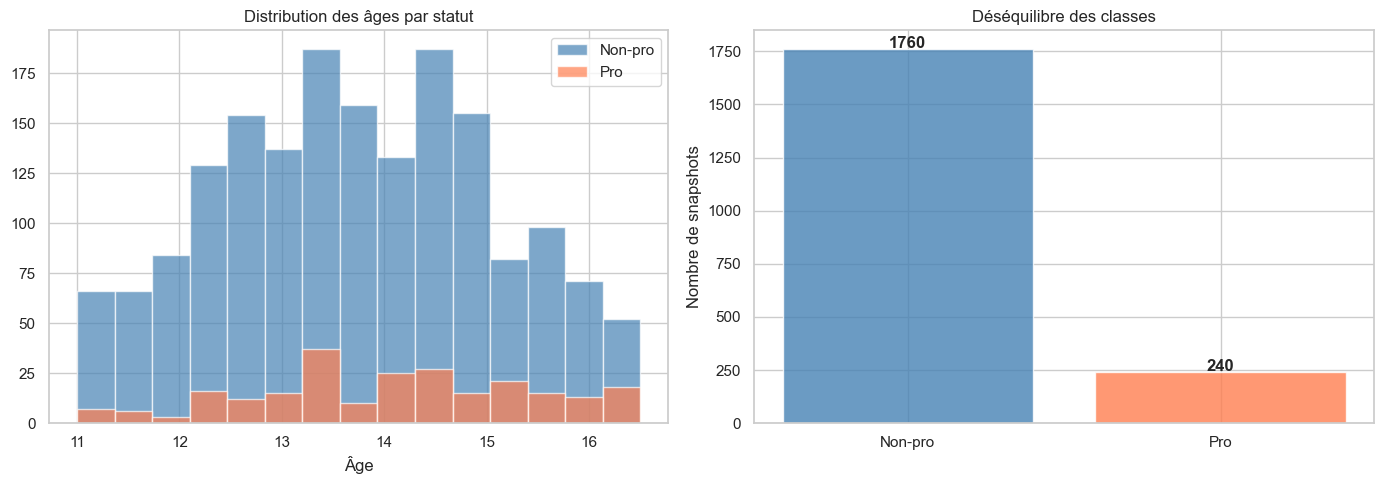

In [25]:
# Distribution des âges par statut
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for label, color, name in [(0, 'steelblue', 'Non-pro'), (1, 'coral', 'Pro')]:
    df[df['is_pro'] == label]['age'].hist(
        bins=15, ax=axes[0], alpha=0.7, color=color, label=name
    )
axes[0].set_title('Distribution des âges par statut')
axes[0].set_xlabel('Âge')
axes[0].legend()

counts = df['is_pro'].value_counts().sort_index()
axes[1].bar(['Non-pro', 'Pro'], counts.values, color=['steelblue', 'coral'], alpha=0.8)
axes[1].set_title('Déséquilibre des classes')
axes[1].set_ylabel('Nombre de snapshots')
for i, v in enumerate(counts.values):
    axes[1].text(i, v + 5, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

In [26]:
# Aperçu de la couverture scout et de la fiabilité
print('=== COUVERTURE SCOUT ===')
print(df['scout_coverage'].value_counts().sort_index())
print()
print('=== FIABILITÉ DES SCORES ===')
print(df['score_reliability'].value_counts())
print()
print('=== ALERTES SCOUT ===')
print(df['scout_alert'].value_counts(dropna=False))

=== COUVERTURE SCOUT ===
scout_coverage
1    664
2    661
3    675
Name: count, dtype: int64

=== FIABILITÉ DES SCORES ===
score_reliability
high      1152
medium     754
low         94
Name: count, dtype: int64

=== ALERTES SCOUT ===
scout_alert
NaN               1915
scout_confirme      73
scout_alerte        12
Name: count, dtype: int64


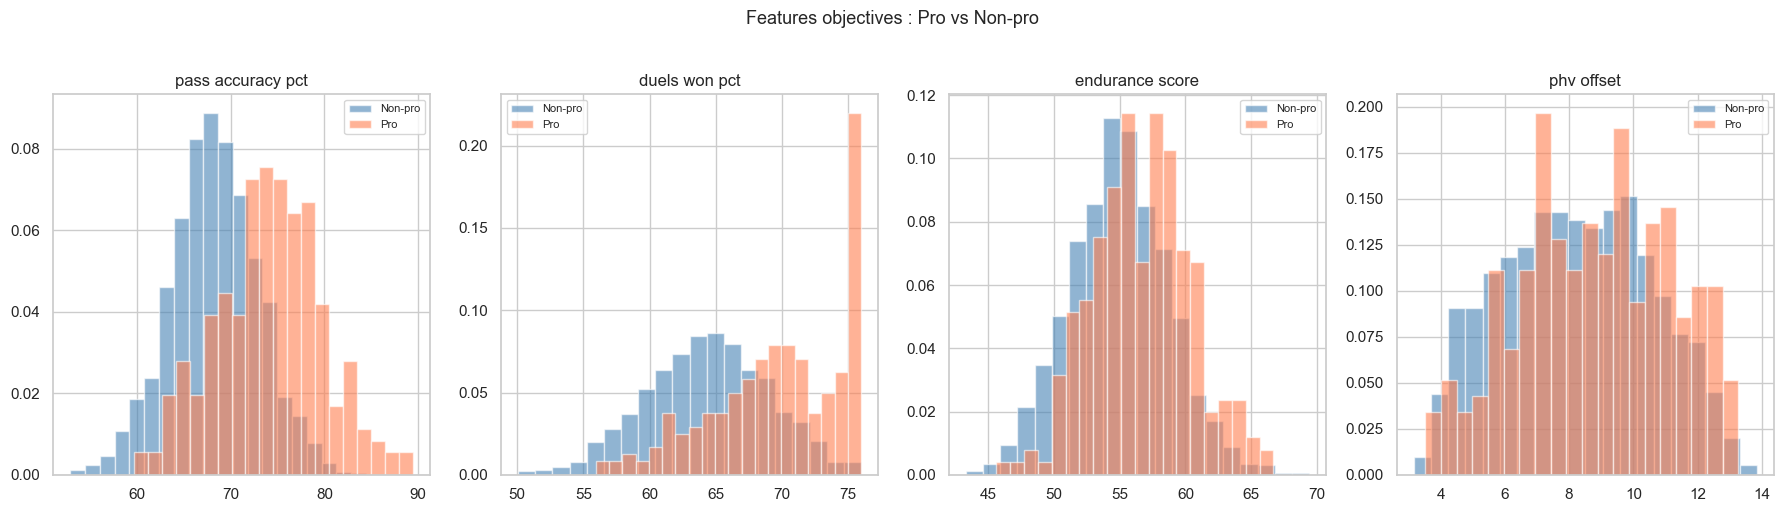

In [27]:
# Comparaison pros vs non-pros sur les features objectives clés
metrics_to_compare = [
    'pass_accuracy_pct', 'duels_won_pct',
    'endurance_score',   'phv_offset',
]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for i, metric in enumerate(metrics_to_compare):
    if metric not in df.columns:
        continue
    pro_vals    = df[df['is_pro'] == 1][metric].dropna()
    nonpro_vals = df[df['is_pro'] == 0][metric].dropna()
    axes[i].hist(nonpro_vals, bins=20, alpha=0.6, color='steelblue', label='Non-pro', density=True)
    axes[i].hist(pro_vals,    bins=20, alpha=0.6, color='coral',     label='Pro',     density=True)
    axes[i].set_title(metric.replace('_', ' '))
    axes[i].legend(fontsize=8)

plt.suptitle('Features objectives : Pro vs Non-pro', y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

---
## 3. Entraînement du modèle (features objectives uniquement)

In [28]:
# Split stratifié par joueur
df_train, df_test = temporal_train_test_split(df, test_ratio=0.20)

Train : 1600 snapshots (192 pros) — 400 joueurs
Test  : 400 snapshots (48 pros) — 100 joueurs


In [29]:
# Mode objectif forcé — le scout ne rentre PAS dans le modèle ML
# select_features_for_dataset() activerait le bonus scout sur données synthétiques
# car tous les joueurs ont des observations générées automatiquement.
# Sur vraies données, une partie des joueurs n'aura pas de scout → mode objectif naturel.
feature_cols = get_core_feature_columns(df_train)
print(f'Mode : objectif forcé — scout retiré du modèle ML')
print(f'Nombre de features : {len(feature_cols)}')
print(f'Features : {feature_cols}')

Mode : objectif forcé — scout retiré du modèle ML
Nombre de features : 11
Features : ['phv_offset', 'phv_zscore_jump', 'pass_accuracy_pct', 'duels_won_pct', 'adj_pass_accuracy_pct', 'adj_duels_won_pct', 'delta_pass_accuracy_pct', 'delta_endurance_score', 'delta_duels_won_pct', 'age', 'competition_level']


In [30]:
pipeline, used_features = train_model(df_train, feature_cols)

Entraînement sur 1600 exemples, 11 features...
Entraînement terminé.


---
## 4. Évaluation

In [31]:
optimal_threshold = find_optimal_threshold(pipeline, df_train, used_features)

Seuil optimal : 0.56  (F1 pro CV : 0.578)



RÉSULTATS D'ÉVALUATION
Seuil utilisé        : 0.56
AUC-ROC              : 0.880
Average Precision    : 0.659

              precision    recall  f1-score   support

     Non-pro       0.94      0.95      0.95       352
         Pro       0.62      0.58      0.60        48

    accuracy                           0.91       400
   macro avg       0.78      0.77      0.77       400
weighted avg       0.91      0.91      0.91       400



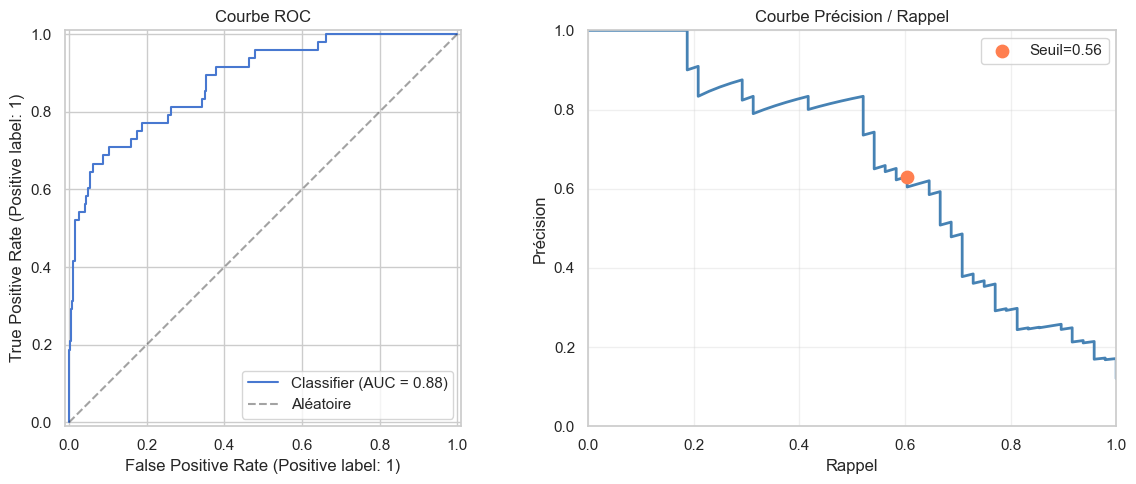

In [32]:
results = evaluate_model(pipeline, df_test, used_features,
                         threshold=optimal_threshold, plot=True)

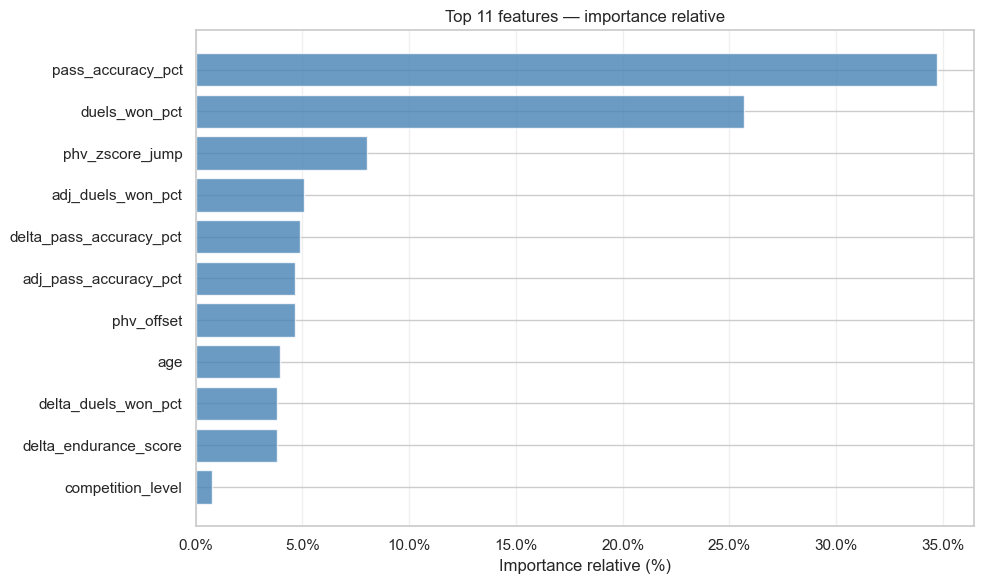

In [33]:
# Feature importance — le scout ne devrait plus dominer
importance_dict = plot_feature_importance(pipeline, used_features, top_n=15)

---
## 5. Scores de potentiel avec fiabilité

In [34]:
scores = predict_potential(pipeline, df_test, used_features)

print('Top 15 joueurs — score objectif + contexte scout :')
cols_to_show = ['player_id', 'age', 'potential_score',
                'score_reliability', 'scout_coverage', 'scout_alert']
cols_available = [c for c in cols_to_show if c in scores.columns]
print(scores[cols_available].head(15).to_string(index=False))

Top 15 joueurs — score objectif + contexte scout :
player_id  age  potential_score score_reliability  scout_coverage    scout_alert
    P0235 16.1             94.1            medium               2 scout_confirme
    P0468 16.4             92.3            medium               2 scout_confirme
    P0269 16.3             92.2            medium               3 scout_confirme
    P0180 15.3             90.6            medium               1            NaN
    P0269 15.3             90.1              high               3 scout_confirme
    P0424 16.3             88.6               low               1            NaN
    P0198 13.1             84.9              high               2 scout_confirme
    P0180 16.3             84.8            medium               3 scout_confirme
    P0424 15.3             84.5            medium               1            NaN
    P0389 14.0             83.6              high               2            NaN
    P0130 16.0             83.3              high         

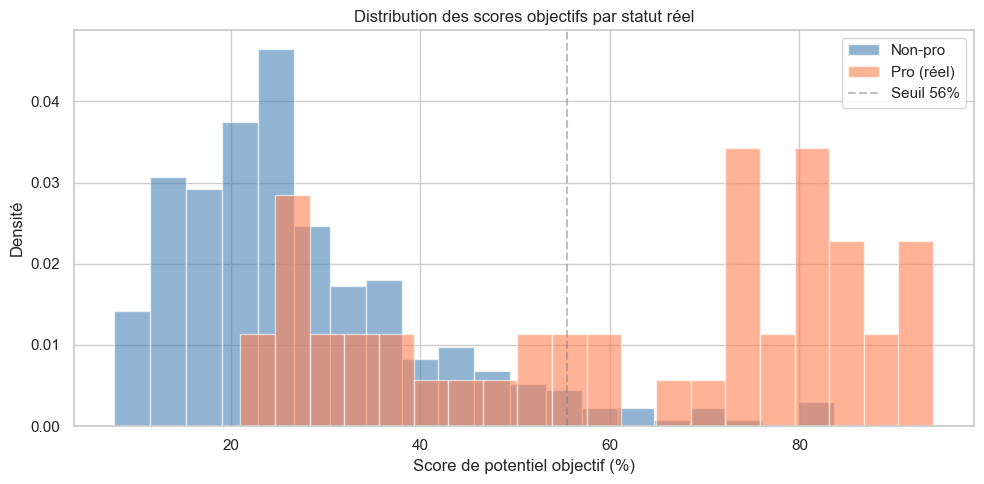

In [36]:
# Distribution des scores objectifs par statut réel
if 'is_pro' in scores.columns:
    fig, ax = plt.subplots(figsize=(10, 5))
    pro_scores    = scores[scores['is_pro'] == 1]['potential_score']
    nonpro_scores = scores[scores['is_pro'] == 0]['potential_score']
    ax.hist(nonpro_scores, bins=20, alpha=0.6, color='steelblue', label='Non-pro', density=True)
    ax.hist(pro_scores,    bins=20, alpha=0.6, color='coral',     label='Pro (réel)', density=True)
    ax.axvline(optimal_threshold * 100, color='gray', linestyle='--',
               alpha=0.5, label=f'Seuil {optimal_threshold*100:.0f}%')
    ax.set_xlabel('Score de potentiel objectif (%)')
    ax.set_ylabel('Densité')
    ax.set_title('Distribution des scores objectifs par statut réel')
    ax.legend()
    plt.tight_layout()
    plt.show()

---
## 6. Similarité Mahalanobis

In [39]:
pro_db_combined = build_reference_database(
    also_add_synthetic_pros = True,
    df_synthetic            = df_train,
)

Modèle de similarité ajusté sur 204 snapshots pros, 11 features.
Base combinée : 12 profils réels + 192 synthétiques


In [40]:
pro_test_ids    = df_test[df_test['is_pro'] == 1]['player_id'].unique()
nonpro_test_ids = df_test[df_test['is_pro'] == 0]['player_id'].unique()

report_pro = build_similarity_report(
    player_id  = pro_test_ids[0],
    df         = df_test,
    pro_db     = pro_db_combined,
    top_k      = 3,
    age_window = 1.5,
)
print_similarity_report(report_pro, df_test)


RAPPORT DE SIMILARITÉ — Joueur P0027
Statut réel : PRO ✓

  Snapshot à 11.3 ans (saison 2020-21) :
    1. Profil académie #P0157 (âge 12.6) similarité= 51.1% █████
    2. Profil académie #P0383 (âge 11.3) similarité= 46.0% ████
    3. Profil académie #P0383 (âge 12.3) similarité= 44.9% ████

  Snapshot à 12.3 ans (saison 2021-22) :
    1. Profil académie #P0256 (âge 11.4) similarité= 66.5% ██████
    2. Profil académie #P0237 (âge 12.4) similarité= 46.2% ████
    3. Profil académie #P0172 (âge 12.8) similarité= 44.7% ████

  Snapshot à 13.3 ans (saison 2022-23) :
    1. Profil académie #P0381 (âge 12.7) similarité= 58.0% █████
    2. Profil académie #P0272 (âge 14.2) similarité= 45.4% ████
    3. Profil académie #P0210 (âge 14.0) similarité= 44.9% ████

  Snapshot à 14.3 ans (saison 2023-24) :
    1. Profil académie #P0192 (âge 15.1) similarité= 60.1% ██████
    2. Profil académie #P0255 (âge 14.3) similarité= 55.1% █████
    3. Profil académie #P0048 (âge 14.4) similarité= 55.1% ████

---
## 7. Classement composite — score objectif + similarité + alerte scout

In [41]:
print('=== CLASSEMENT COMPOSITE (ML objectif + Similarité Mahalanobis) ===\n')
print(f"{'Joueur':<10} {'Statut':<10} {'ML obj.':>8} {'Traj.':>7} "
      f"{'Composite':>10} {'Scout':>15} {'Interprétation'}")
print('-' * 95)

composite_rows = []

for pid in df_test['player_id'].unique():
    row_df  = df_test[df_test['player_id'] == pid]
    is_pro  = int(row_df['is_pro'].iloc[0])

    # Score ML objectif (dernier snapshot)
    available = [c for c in used_features if c in df_test.columns]
    last_snap = row_df.sort_values('age').iloc[[-1]]
    ml_proba  = pipeline.predict_proba(last_snap[available].values)[0][1]
    ml_score  = round(ml_proba * 100, 1)

    # Récupérer les indicateurs scout (affichage seulement)
    scout_alert    = last_snap['scout_alert'].iloc[0] if 'scout_alert' in last_snap.columns else None
    reliability    = last_snap['score_reliability'].iloc[0] if 'score_reliability' in last_snap.columns else '?'
    scout_coverage = int(last_snap['scout_coverage'].iloc[0]) if 'scout_coverage' in last_snap.columns else 0

    # Score trajectoire Mahalanobis
    traj       = compute_trajectory_similarity(pid, df_test, pro_db_combined, age_window=2.0)
    traj_score = traj.get('trajectory_score', 0.0)
    trend      = traj.get('trend', 'unknown')

    # Composite : 65% ML objectif + 35% similarité (scout retiré du calcul)
    composite = round(0.65 * ml_score + 0.35 * traj_score, 1)

    # Interprétation
    if composite >= 55 and trend == 'improving':
        interpretation = '🟢 Très prometteur'
    elif composite >= 50:
        interpretation = '🟡 À surveiller'
    elif composite >= 40:
        interpretation = '🟠 Incertain'
    else:
        interpretation = '🔴 Éloigné profil pro'

    # Affichage du signal scout séparé
    scout_display = '—'
    if scout_alert == 'scout_confirme':
        scout_display = '✓ confirme'
    elif scout_alert == 'scout_alerte':
        scout_display = '⚠ alerte'
    elif scout_coverage == 0:
        scout_display = 'non observé'

    composite_rows.append({
        'player_id': pid, 'is_pro': is_pro, 'ml_score': ml_score,
        'traj_score': traj_score, 'composite': composite,
        'trend': trend, 'interpretation': interpretation,
        'scout_display': scout_display, 'reliability': reliability,
    })

composite_rows.sort(key=lambda x: x['composite'], reverse=True)

for r in composite_rows[:20]:
    status = 'PRO ✓' if r['is_pro'] == 1 else 'Non-pro'
    print(f"{r['player_id']:<10} {status:<10} {r['ml_score']:>7.1f}% "
          f"{r['traj_score']:>6.1f}% {r['composite']:>9.1f}% "
          f"{r['scout_display']:>15}  {r['interpretation']}")

print('\n=== VALIDATION ===')
pros_in_top10 = sum(1 for r in composite_rows[:10]  if r['is_pro'] == 1)
pros_in_top20 = sum(1 for r in composite_rows[:20]  if r['is_pro'] == 1)
total_pros    = sum(1 for r in composite_rows        if r['is_pro'] == 1)
print(f'Pros dans le top 10  : {pros_in_top10}/10')
print(f'Pros dans le top 20  : {pros_in_top20}/20  ({pros_in_top20/total_pros*100:.0f}% de tous les pros)')
print(f'Total pros dans test : {total_pros}')

=== CLASSEMENT COMPOSITE (ML objectif + Similarité Mahalanobis) ===

Joueur     Statut      ML obj.   Traj.  Composite           Scout Interprétation
-----------------------------------------------------------------------------------------------
P0235      PRO ✓         94.1%   65.0%      83.9%      ✓ confirme  🟢 Très prometteur
P0269      PRO ✓         92.2%   58.4%      80.4%      ✓ confirme  🟢 Très prometteur
P0468      PRO ✓         92.3%   53.6%      78.8%      ✓ confirme  🟢 Très prometteur
P0130      PRO ✓         83.3%   62.8%      76.1%      ✓ confirme  🟢 Très prometteur
P0180      PRO ✓         84.8%   57.1%      75.1%      ✓ confirme  🟡 À surveiller
P0424      PRO ✓         88.6%   47.5%      74.2%               —  🟡 À surveiller
P0310      Non-pro       80.6%   60.5%      73.6%               —  🟢 Très prometteur
P0105      Non-pro       83.0%   53.1%      72.5%               —  🟢 Très prometteur
P0070      PRO ✓         82.8%   52.5%      72.2%               —  🟢 Très promet

---
## 8. Explication individuelle SHAP

In [ ]:
sample_pro_id = df_test[df_test['is_pro'] == 1]['player_id'].iloc[0]
print(f'Joueur sélectionné : {sample_pro_id}')

# Fix SHAP : versions récentes retournent shape (N, 2) pour RandomForest binaire
# On extrait manuellement les valeurs pour la classe 1 (pro)
import shap

player_df = df_test[df_test['player_id'] == sample_pro_id].sort_values('age')
available = [c for c in used_features if c in df_test.columns]
snapshot  = player_df.iloc[-1]
X_player  = snapshot[available].values.reshape(1, -1)
X_transformed = pipeline[:-1].transform(X_player)
clf = pipeline.named_steps['clf']

proba = pipeline.predict_proba(X_player)[0][1]
reliability = snapshot.get('score_reliability', '?')
print(f'Score ML objectif : {proba:.1%}  |  Fiabilité : {reliability}')

explainer = shap.TreeExplainer(clf)
shap_values = explainer.shap_values(X_transformed)

# Gestion des deux formats selon la version de SHAP
if isinstance(shap_values, list):
    # Ancienne API : liste [classe_0, classe_1]
    sv = shap_values[1][0]
    bv = explainer.expected_value[1] if isinstance(explainer.expected_value, list) else explainer.expected_value
elif hasattr(shap_values, 'shape') and len(shap_values.shape) == 3:
    # Nouvelle API : array (1, n_features, n_classes)
    sv = shap_values[0, :, 1]
    bv = explainer.expected_value[1] if hasattr(explainer.expected_value, '__len__') else explainer.expected_value
elif hasattr(shap_values, 'shape') and len(shap_values.shape) == 2:
    # Nouvelle API : array (n_features, n_classes)
    sv = shap_values[:, 1]
    bv = explainer.expected_value[1] if hasattr(explainer.expected_value, '__len__') else explainer.expected_value
else:
    sv = shap_values[0]
    bv = explainer.expected_value

shap.waterfall_plot(
    shap.Explanation(
        values        = sv,
        base_values   = float(bv),
        data          = X_transformed[0],
        feature_names = available,
    ),
    max_display=15,
)

---
## 9. Sauvegarde

In [42]:
import pickle

os.makedirs('../data/processed', exist_ok=True)

model_path = '../data/processed/uroom_model_v2.pkl'
with open(model_path, 'wb') as f:
    pickle.dump({
        'pipeline':  pipeline,
        'features':  used_features,
        'threshold': optimal_threshold,
        'mode':      'objective',  # scout retiré du modèle ML
    }, f)

df.to_csv('../data/processed/feature_matrix_v2.csv', index=False)

print(f'Modèle v2 sauvegardé : {model_path}')
print(f'Mode : objectif-first (scout = signal d alerte séparé)')

Modèle v2 sauvegardé : ../data/processed/uroom_model_v2.pkl
Mode : objectif-first (scout = signal d alerte séparé)
